# <br><center>**EDA – Web Time Series Forecasting**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use("dark_background")
plt.rcParams.update({
    "figure.figsize": (20,12),
    "font.size": 14,
    "axes.grid": True,
    "grid.alpha": 0.2
})
import gc; gc.enable()
from IPython.display import display

pd.set_option("display.max_rows", 6)
pd.set_option("display.max_columns", 100)

from warnings import simplefilter
simplefilter(action="ignore", category=pd.errors.PerformanceWarning)

In [2]:
train = pd.read_csv("../datamount/train_1.csv", index_col="Page").fillna(0).astype("int32"); train

,2015-07-01,2015-07-02,2015-07-03,2015-07-04,2015-07-05,2015-07-06,2015-07-07,2015-07-08,2015-07-09,2015-07-10,2015-07-11,2015-07-12,2015-07-13,2015-07-14,2015-07-15,2015-07-16,2015-07-17,2015-07-18,2015-07-19,2015-07-20,2015-07-21,2015-07-22,2015-07-23,2015-07-24,2015-07-25,2015-07-26,2015-07-27,2015-07-28,2015-07-29,2015-07-30,2015-07-31,2015-08-01,2015-08-02,2015-08-03,2015-08-04,2015-08-05,2015-08-06,2015-08-07,2015-08-08,2015-08-09,2015-08-10,2015-08-11,2015-08-12,2015-08-13,2015-08-14,2015-08-15,2015-08-16,2015-08-17,2015-08-18,2015-08-19,...,2016-11-12,2016-11-13,2016-11-14,2016-11-15,2016-11-16,2016-11-17,2016-11-18,2016-11-19,2016-11-20,2016-11-21,2016-11-22,2016-11-23,2016-11-24,2016-11-25,2016-11-26,2016-11-27,2016-11-28,2016-11-29,2016-11-30,2016-12-01,2016-12-02,2016-12-03,2016-12-04,2016-12-05,2016-12-06,2016-12-07,2016-12-08,2016-12-09,2016-12-10,2016-12-11,2016-12-12,2016-12-13,2016-12-14,2016-12-15,2016-12-16,2016-12-17,2016-12-18,2016-12-19,2016-12-20,2016-12-21,2016-12-22,2016-12-23,2016-12-24,2016-12-25,2016-12-26,2016-12-27,2016-12-28,2016-12-29,2016-12-30,2016-12-31
Page,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2NE1_zh.wikipedia.org_all-access_spider,18,11,5,13,14,9,9,22,26,24,19,10,14,15,8,16,8,8,16,7,11,10,20,18,15,14,49,10,16,18,8,5,9,7,13,9,7,4,11,10,5,9,9,9,9,13,4,15,25,9,...,13,8,15,14,12,6,11,10,42,21,24,14,11,204,14,45,33,28,18,14,47,15,14,18,20,14,16,14,20,60,22,15,17,19,18,21,21,47,65,17,32,63,15,26,14,20,22,19,18,20
2PM_zh.wikipedia.org_all-access_spider,11,14,15,18,11,13,22,11,10,4,41,65,57,38,20,62,44,15,10,47,24,17,22,9,39,13,11,12,21,19,9,15,33,8,8,7,13,2,23,12,27,27,36,23,58,80,60,69,42,161,...,12,11,14,28,23,20,9,12,11,14,14,15,15,11,20,13,19,621,57,17,23,19,21,47,28,22,22,65,27,17,17,13,9,18,22,17,15,22,23,19,17,42,28,15,9,30,52,45,26,20
3C_zh.wikipedia.org_all-access_spider,1,0,1,1,0,4,0,3,4,4,1,1,1,6,8,6,4,5,1,2,3,8,8,6,6,2,2,3,2,4,3,3,5,3,5,4,2,5,1,4,5,0,0,7,3,5,1,6,2,5,...,6,4,2,4,6,5,4,4,3,3,9,3,5,4,0,1,4,5,8,8,1,1,2,5,3,3,3,7,3,9,8,3,210,5,4,6,2,2,4,3,3,1,1,7,4,4,6,3,4,17
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Enamorándome_de_Ramón_es.wikipedia.org_all-access_spider,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Hasta_el_último_hombre_es.wikipedia.org_all-access_spider,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
Francisco_el_matemático_(serie_de_televisión_de_2017)_es.wikipedia.org_all-access_spider,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [3]:
train.info()

<class 'pandas.DataFrame'>
Index: 145063 entries, 2NE1_zh.wikipedia.org_all-access_spider to Francisco_el_matemático_(serie_de_televisión_de_2017)_es.wikipedia.org_all-access_spider
Columns: 550 entries, 2015-07-01 to 2016-12-31
dtypes: int32(550)
memory usage: 313.6 MB


In [4]:
import re
from collections import Counter

def get_language(page):
    res = re.search("[a-z][a-z].wikipedia.org", page)
    if res:
        return res[0][:2]
    return "na"

train["lang"] = train.index.map(get_language)
Counter(train.lang)

Counter({'en': 24108,
         'ja': 20431,
         'de': 18547,
         'na': 17855,
         'fr': 17802,
         'zh': 17229,
         'ru': 15022,
         'es': 14069})

In [5]:
languages = "en ja de na fr zh ru es".split()
lang_sets = {ln:train[train.lang==ln].iloc[:,:-1] for ln in languages}
sums = {k:v.mean(axis=0) for k,v in lang_sets.items()}

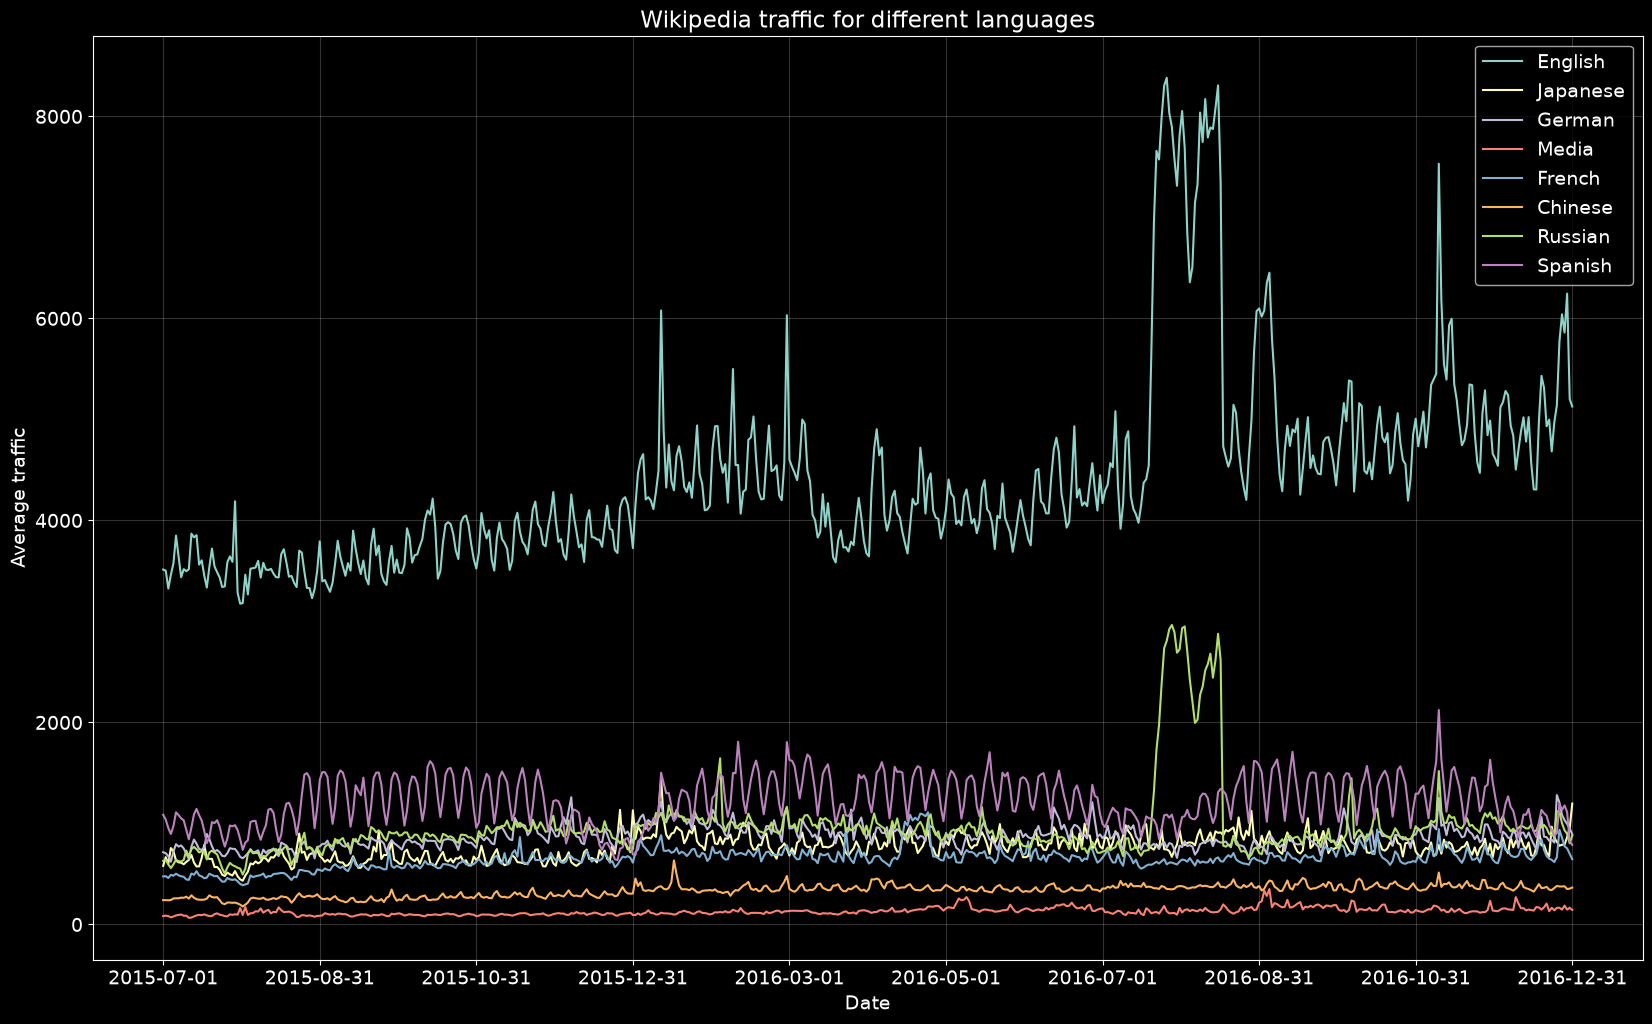

In [6]:
dates = sums["en"].index.tolist()
token2language = {
    "en":"English", "ja":"Japanese", "de":"German",
    "fr":"French", "zh":"Chinese", "ru":"Russian",
    "es":"Spanish", "na":"Media"
}

for ln in sums:
    plt.plot(sums[ln], label=token2language[ln])
plt.legend()
plt.xticks(dates[::61])
plt.xlabel("Date")
plt.ylabel("Average traffic")
plt.title("Wikipedia traffic for different languages")
plt.show()